In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

Age
🧓 Age of the patient (in years)


Sex
🚻 Gender of the patient (1 = male, 0 = female)


Chest pain type
❤️‍🩹 Type of chest pain experienced by the patient


BP
🩸 Resting blood pressure (mm Hg)


Cholesterol
🧪 Serum cholesterol level (mg/dl)

FBS over 120
🍬 Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no)

EKG results
📉 Resting electrocardiogram results

Max HR
🏃‍♂️ Maximum heart rate achieved during exercise

Exercise angina
😣 Exercise-induced angina (1 = yes, 0 = no)

ST depression
📉 ST depression induced by exercise relative to rest

In [2]:
df = pd.read_csv("Heart_Disease_Prediction.csv")
                 

In [3]:
df.head()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence


In [4]:
df.tail()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,Absence
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,Absence
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,Absence
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,Absence
269,67,1,4,160,286,0,2,108,1,1.5,2,3,3,Presence


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      270 non-null    int64  
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              270 non-null    int64  
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            270 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null    int64  
 13  Heart Disease            270 non-null    object 
dtypes: float64(1), int64(12), 

In [6]:
df.describe()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium
count,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.00000,270.000000,270.000000,270.000000
mean,54.433333,0.677778,3.174074,131.344444,249.659259,0.148148,1.022222,149.677778,0.329630,1.05000,1.585185,0.670370,4.696296
std,9.109067,0.468195,0.950090,17.861608,51.686237,0.355906,0.997891,23.165717,0.470952,1.14521,0.614390,0.943896,1.940659
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.00000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,213.000000,0.000000,0.000000,133.000000,0.000000,0.00000,1.000000,0.000000,3.000000
50%,55.000000,1.000000,3.000000,130.000000,245.000000,0.000000,2.000000,153.500000,0.000000,0.80000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,280.000000,0.000000,2.000000,166.000000,1.000000,1.60000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.20000,3.000000,3.000000,7.000000


Pergunta a ser respondida: Quais pacientes são mais propensos a ter uma doença?

In [7]:
#Segunda Etapa: Limpeza de dados

df.isnull().sum()

Age                        0
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                0
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              0
Slope of ST                0
Number of vessels fluro    0
Thallium                   0
Heart Disease              0
dtype: int64

In [8]:
df.min()

Age                             29
Sex                              0
Chest pain type                  1
BP                              94
Cholesterol                    126
FBS over 120                     0
EKG results                      0
Max HR                          71
Exercise angina                  0
ST depression                  0.0
Slope of ST                      1
Number of vessels fluro          0
Thallium                         3
Heart Disease              Absence
dtype: object

In [9]:
df.max()

Age                              77
Sex                               1
Chest pain type                   4
BP                              200
Cholesterol                     564
FBS over 120                      1
EKG results                       2
Max HR                          202
Exercise angina                   1
ST depression                   6.2
Slope of ST                       3
Number of vessels fluro           3
Thallium                          7
Heart Disease              Presence
dtype: object

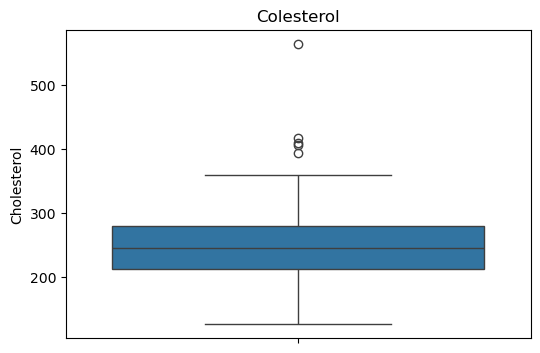

In [10]:
# Implementar boxplot
plt.figure(figsize = (6,4))
sns.boxplot(data=df, y = "Cholesterol")
plt.title('Colesterol')
plt.show()


In [11]:
# O valor acima de 500 mostra um valor incomum para colesterol. Logo, deve ser retirado.

In [12]:
df = df[df['Cholesterol'] != 564]

In [13]:
df.max()

Age                              77
Sex                               1
Chest pain type                   4
BP                              200
Cholesterol                     417
FBS over 120                      1
EKG results                       2
Max HR                          202
Exercise angina                   1
ST depression                   6.2
Slope of ST                       3
Number of vessels fluro           3
Thallium                          7
Heart Disease              Presence
dtype: object

Foi retirado outliers da coluna colesterol. 

# Análise dos dados

In [14]:
# Análise dos dados

comparativo_homens_mulheres_doentes = pd.crosstab(df['Sex'],  df['Heart Disease'], normalize = "index")

display(comparativo_homens_mulheres_doentes)

Heart Disease,Absence,Presence
Sex,,
0,0.767442,0.232558
1,0.453552,0.546448


In [15]:
df['faixa_idade'] = pd.cut(
    df['Age'],
    bins = [28,39,49,59,69,79],
    labels = ['29-39','40-49','50-59','60-69','70-79'])

comparativo__idade_homens_mulheres_doentes = pd.crosstab(df['faixa_idade'],  df['Heart Disease'], normalize = "index")

display(comparativo__idade_homens_mulheres_doentes)


Heart Disease,Absence,Presence
faixa_idade,,
29-39,0.666667,0.333333
40-49,0.716418,0.283582
50-59,0.542056,0.457944
60-69,0.397260,0.602740
70-79,0.600000,0.400000


Até o momento, pode-se tirar 2 conclusões: 

1) Na amostra, os homens possuem maior proporção na identificação de doença de coração;

2) Proporcionalmente, A faixa de idade que houve mais casos está entre 60 e 69 anos;


Agora é necessário analisar quais características os pacientes tem que fazem com que eles sejam propensos a ter essa doença.

In [16]:
chest_pain = pd.crosstab(df['Chest pain type'], df['Heart Disease'], normalize = "index")

display(chest_pain)

Heart Disease,Absence,Presence
Chest pain type,,
1,0.750000,0.250000
2,0.833333,0.166667
3,0.782051,0.217949
4,0.294574,0.705426


In [17]:
df['Fc_max_estimado'] = 220 - df['Age']

df['Percentual_FC_Max'] = (df['Max HR'] / df['Fc_max_estimado']) * 100



comparacao_hr = pd.crosstab(pd.cut(df['Percentual_FC_Max'],
                                  bins = [0, 70, 85, 100, float('inf')],
                                  labels = ["Até 70%", "71 - 85%", "85 - 100", "100+"], include_lowest=True), df['Heart Disease'], normalize = "index")

display(comparacao_hr)

Heart Disease,Absence,Presence
Percentual_FC_Max,,
Até 70%,0.153846,0.846154
71 - 85%,0.339286,0.660714
85 - 100,0.679389,0.320611
100+,0.660714,0.339286


In [18]:
df['faixa_bp'] = pd.cut(
    df['BP'],
    bins = [0,120,129,139,200],
    labels = ["Até 120 mmHG", "121-129 mmHG","130-139 mmHG","140 ou mais mmHG"])

BP = pd.crosstab(df['faixa_bp'], df['Heart Disease'],normalize="index")

display(BP)

Heart Disease,Absence,Presence
faixa_bp,,
Até 120 mmHG,0.633333,0.366667
121-129 mmHG,0.437500,0.562500
130-139 mmHG,0.610169,0.389831
140 ou mais mmHG,0.477273,0.522727


In [19]:
df['Faixa_colesterol'] = pd.cut(
    df['Cholesterol'],
    bins = [0,199,239, 564],
    labels = ["Normal -> 0-199", "Borderline -> 200-239", "High Risk -> 240+"])

colesterol = pd.crosstab(df['Faixa_colesterol'], df['Heart Disease'],normalize = "index")

display(colesterol)

Heart Disease,Absence,Presence
Faixa_colesterol,,
Normal -> 0-199,0.641026,0.358974
Borderline -> 200-239,0.630952,0.369048
High Risk -> 240+,0.486301,0.513699


In [20]:
sugar = pd.crosstab(df['FBS over 120'], df['Heart Disease'],normalize = "index")

display(sugar)

Heart Disease,Absence,Presence
FBS over 120,,
0,0.550218,0.449782
1,0.575000,0.425000


In [21]:
EKG = pd.crosstab(df['EKG results'], df['Heart Disease'],normalize = "index")

display(EKG)

Heart Disease,Absence,Presence
EKG results,,
0,0.648855,0.351145
1,0.500000,0.500000
2,0.463235,0.536765


In [22]:
exercise_angina = pd.crosstab(df['Exercise angina'], df['Heart Disease'],normalize = "index")

display(exercise_angina)

Heart Disease,Absence,Presence
Exercise angina,,
0,0.700000,0.300000
1,0.258427,0.741573


In [23]:
df['Faixa_ST'] = pd.cut(
    df['ST depression'],
    bins = [-0.01,1,2, 7],
    labels = ["Normal -> 0-1", "Suspeito -> 1-2", "Alto Suspeito -> 2+"])

ST_Depression = pd.crosstab(df['Faixa_ST'], df['Heart Disease'],normalize = "index")

display(ST_Depression)

Heart Disease,Absence,Presence
Faixa_ST,,
Normal -> 0-1,0.700637,0.299363
Suspeito -> 1-2,0.470588,0.529412
Alto Suspeito -> 2+,0.159091,0.840909


In [24]:
Slope_st = pd.crosstab(df['Slope of ST'], df['Heart Disease'],normalize = "index")

display(Slope_st)

Heart Disease,Absence,Presence
Slope of ST,,
1,0.753846,0.246154
2,0.355372,0.644628
3,0.444444,0.555556


In [25]:
vessels = pd.crosstab(df['Number of vessels fluro'], df['Heart Disease'],normalize = "index")

display(vessels)

Heart Disease,Absence,Presence
Number of vessels fluro,,
0,0.748428,0.251572
1,0.344828,0.655172
2,0.212121,0.787879
3,0.157895,0.842105


In [26]:
thallium = pd.crosstab(df['Thallium'], df['Heart Disease'],normalize = "index")

display(thallium)

Heart Disease,Absence,Presence
Thallium,,
3,0.782895,0.217105
6,0.428571,0.571429
7,0.233010,0.766990


Pela análise, 7 variáveis se apresentam ,proporcionalmente falando, como as que mais demonstram pessoas que estão propensas ou possuem a doença:

1)Chest_Pain -> 70% das pessoas que tem dor nível 4 e possuem a doença;

2)Percentual Fc_max -> Proporcionalmente, pessoas que tiveram um percentual até de 70% mostram ter uma presença maior de doença.

3)BP -> Proporcionalmente falando, aquelas que tem hipertensão 2 e possuem um BP(Blood Pressure) elevado possuem a doença(Em torno de 53% das pessoas)

4)Colesterol -> Aqueles que ultrapassam a faixa de 240 de colesterol possuem proporcionalmente maior doença no coração.;

5)Vessels -> Um dos indicadores principais é quando se tem como resultado maior que 0. Percebe-se proporcionalmente que aqueles que obtiveram um resultado maior que 0, possuem a doença.

6)Exercise_Angina -> A grande maioria que obtve resultado positivo no teste possui a doença, sendo 74% deles.

7)Thallium -> Uma das variáveis que indica também uma alta taxa. Aqueles que tiveram um resultado igual a 6 ou 7, em sua grande parte possuem a doença; 57% daqueles que obtiveram 6 tem a doença e 75% daqueles que obtiveram resultado 7 tem a doença.

Embora haja a análise dessas variáveis, é possível notar que há muitas pessoas que, embora o resultado tenha saído normal, possuem alguma doença no coração. Logo, é importante cruzar dados para garantir que identifique logo essas doenças. 

Assim, o próximo passo será uma análise com gráficos, depois o uso de machine learning para previsão.

# ANÁLISE COM GRÁFICOS


A análise dos gráficos a seguir foi feito a partir das principais variáveis da análise do dataset.

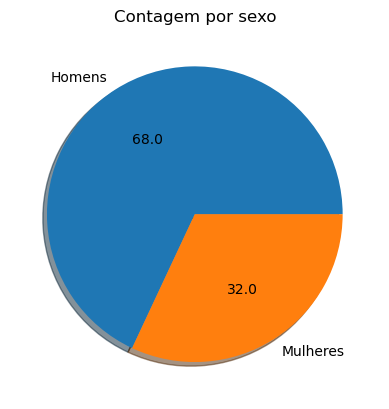

In [27]:
sexo = df['Sex'].value_counts()

plt.pie(sexo, labels = ["Homens", "Mulheres"],
       autopct = "%1.1f",
       shadow = True)

plt.title("Contagem por sexo")

plt.show()

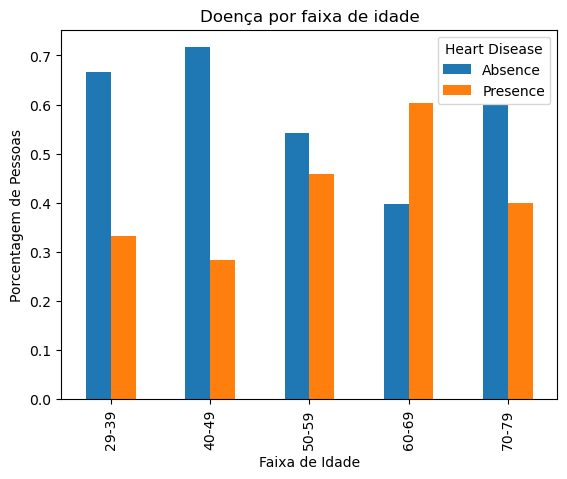

In [28]:
comparativo__idade_homens_mulheres_doentes.plot(kind = "bar")

plt.xlabel("Faixa de Idade")
plt.ylabel("Porcentagem de Pessoas") 
plt.title("Doença por faixa de idade")
plt.show()

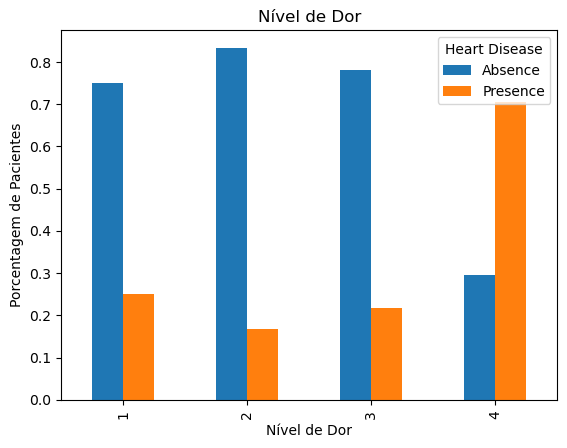

In [29]:
chest_pain.plot(kind = "bar")

plt.title("Nível de Dor")

plt.xlabel("Nível de Dor")
plt.ylabel("Porcentagem de Pacientes")

plt.show()

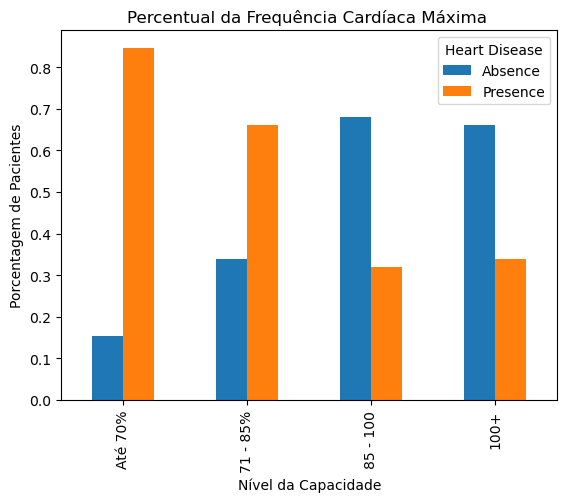

In [30]:
comparacao_hr.plot(kind = "bar")

plt.title("Percentual da Frequência Cardíaca Máxima ")

plt.xlabel("Nível da Capacidade")
plt.ylabel("Porcentagem de Pacientes")

plt.show()

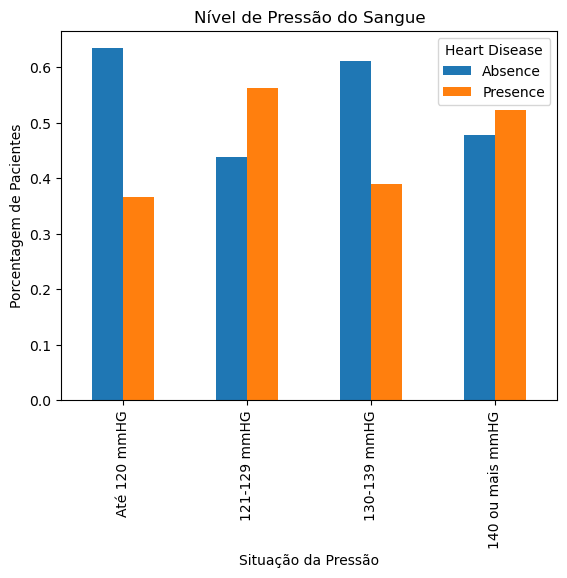

In [31]:
BP.plot(kind = "bar")

plt.title("Nível de Pressão do Sangue")

plt.xlabel("Situação da Pressão")
plt.ylabel("Porcentagem de Pacientes")

plt.show()

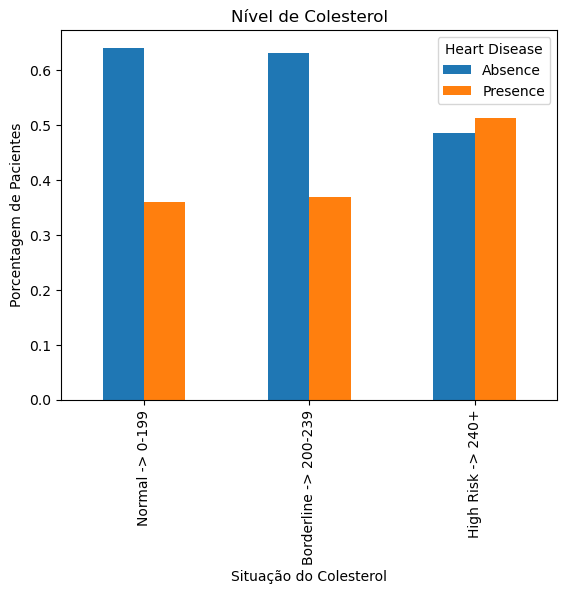

In [32]:
colesterol.plot(kind = "bar")

plt.title("Nível de Colesterol")

plt.xlabel("Situação do Colesterol")
plt.ylabel("Porcentagem de Pacientes")

plt.show()

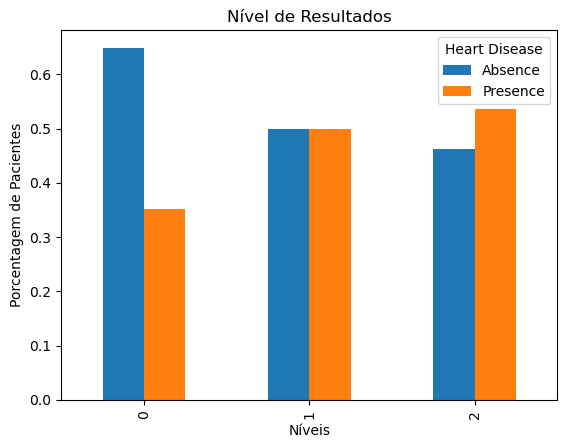

In [33]:
EKG.plot(kind = "bar")

plt.title("Nível de Resultados")

plt.xlabel("Níveis")
plt.ylabel("Porcentagem de Pacientes")

plt.show()

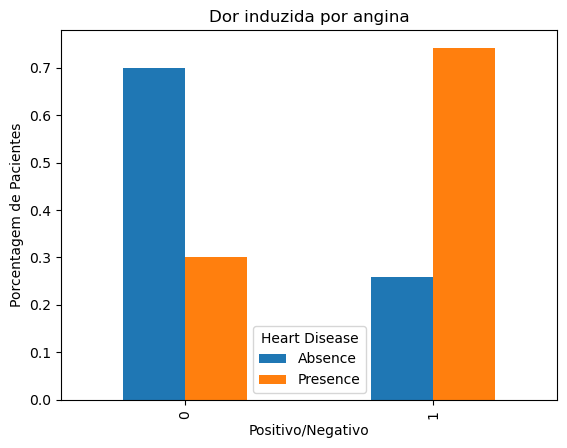

In [34]:
exercise_angina.plot(kind = "bar")

plt.title("Dor induzida por angina")

plt.xlabel("Positivo/Negativo")
plt.ylabel("Porcentagem de Pacientes")

plt.show()

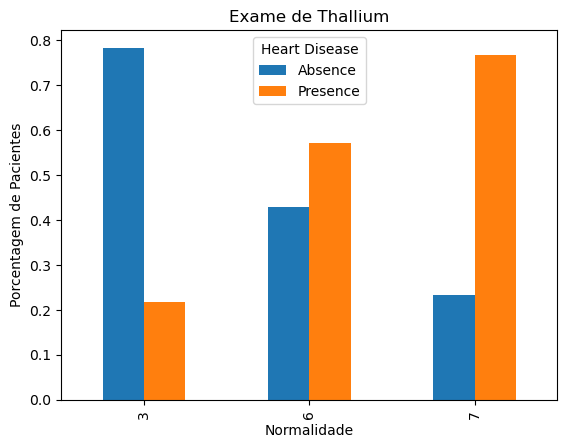

In [35]:
thallium.plot(kind = "bar")

plt.title("Exame de Thallium")

plt.xlabel("Normalidade")
plt.ylabel("Porcentagem de Pacientes")

plt.show()

# APLICAÇÃO DO MACHINE LEARNING

In [36]:
categorias = ['Chest pain type', 'EKG results', 'Slope of ST', 'Thallium', 'Number of vessels fluro'] 
numericos = ['Age', 'BP', 'Cholesterol', 'Max HR', 'ST depression']
binario = ['Sex', 'FBS over 120', 'Exercise angina']

prep = ColumnTransformer([
    ('num', StandardScaler(), numericos),
    ('cat', OneHotEncoder(drop = 'first', handle_unknown='ignore'), categorias),
    ('bin', 'passthrough', binario)

])

In [37]:
# Esse x são valores que serão testados. O drop é usado para tirar essa coluna, deixando o resto
#Já o y é o valor alvo;


features = ['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina',
           'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium']

X = df[features]
y = (df['Heart Disease'] == "Presence").astype(int)

In [38]:
#X_train são os dados usados para treinar. Já o X_test são os dados que vão ser usados para ver se acertou ou não. Ou para testar depois.
# O modelo nunca vê X_test durante o treino.

#Test_size é para saber quanto dos dados vai ser usado para o X_test. Ou seja, como está 0.2, 20% dos dados serão usados para o X_test e 80% dos dados serão usados para treinar.

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size= 0.2, stratify = y, random_state= 42)

# CRIAÇÃO DOS PIPELINES

In [39]:
pipeline_lr = Pipeline([
    ('prep', prep),
    ('model', LogisticRegression(max_iter = 1000))
])

In [40]:
pipeline_xg = Pipeline([
    ('prep', prep),
    ('model', XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    eval_metric='logloss'
        
    ))
])

# VALIDAÇÃO CRUZADA

In [41]:
# Serve para identificar qual o melhor modelo para treinamento

# Será utilizado o Logistic Regression e o XGBoost 

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline = DummyClassifier(
    strategy='prior'
)

modelos = {
    'Baseline': baseline,
    'Regressão Logística': pipeline_lr,
    'XGBoost': pipeline_xg,
}

for nome, m in modelos.items():
    r = cross_validate(m, X_train, y_train, cv=cv,
                       scoring=['accuracy', 'recall', 'f1', 'roc_auc'])
    print(f"{nome}: acc={r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f}  "
          f"recall={r['test_recall'].mean():.3f} "
          f"f1={r['test_f1'].mean():.3f} "
          f"auc={r['test_roc_auc'].mean():.3f}")

Baseline: acc=0.553 ± 0.009  recall=0.000 f1=0.000 auc=0.500
Regressão Logística: acc=0.809 ± 0.054  recall=0.761 f1=0.783 auc=0.887
XGBoost: acc=0.777 ± 0.065  recall=0.760 f1=0.755 auc=0.853


In [42]:
# Os modelos se saíram semelhantes, no entanto, o Logistic Regression se saiu levemente superior ao XGBoost. 

# LOGISTIC REGRESSION

In [43]:
pipeline_lr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Age','Sex','Chest pain type',...,'Slope of ST','Number of vessels fluro', 'Thallium']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthr

In [44]:
y_pred_lr = pipeline_lr.predict(X_test)

In [45]:
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.9074074074074074
              precision    recall  f1-score   support

           0       0.93      0.90      0.92        30
           1       0.88      0.92      0.90        24

    accuracy                           0.91        54
   macro avg       0.91      0.91      0.91        54
weighted avg       0.91      0.91      0.91        54



In [46]:
y_prob = pipeline_lr.predict_proba(X_test)[:, 1]

print(
    f'ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}'
)

ROC-AUC: 0.957


# Resultados

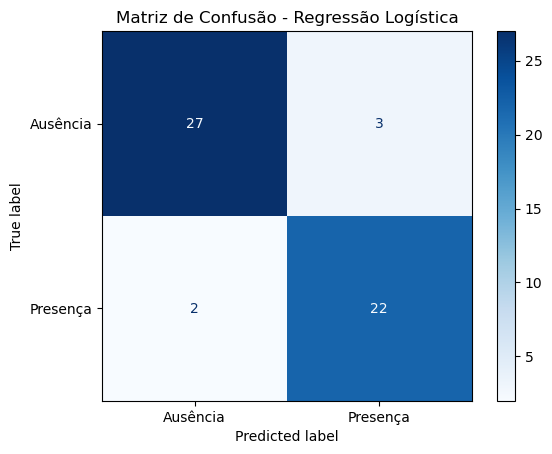

In [47]:
ConfusionMatrixDisplay.from_estimator(
    pipeline_lr,
    X_test,
    y_test,
    display_labels=['Ausência', 'Presença'],
    cmap='Blues'
)

plt.title('Matriz de Confusão - Regressão Logística')
plt.show()

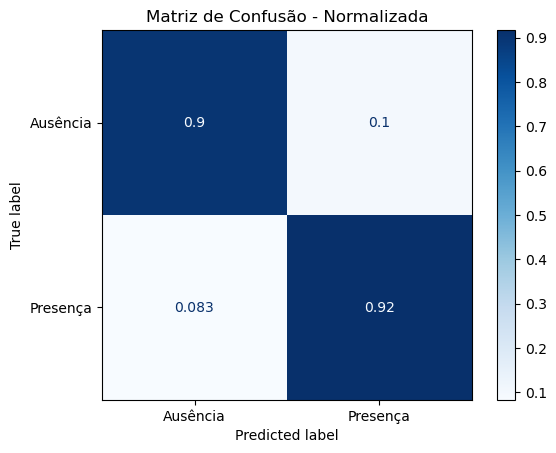

In [48]:
ConfusionMatrixDisplay.from_estimator(
    pipeline_lr,
    X_test,
    y_test,
    display_labels=['Ausência', 'Presença'],
    normalize = 'true',
    cmap='Blues'
)

plt.title('Matriz de Confusão - Normalizada')
plt.show()

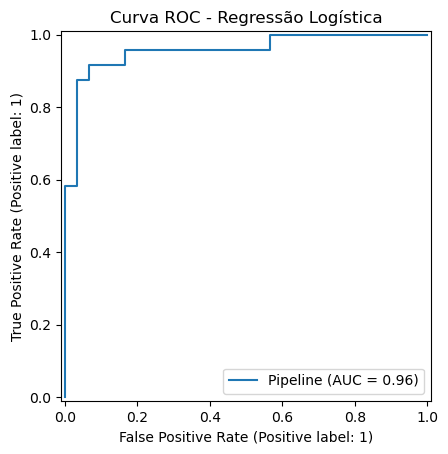

In [49]:
RocCurveDisplay.from_estimator(
    pipeline_lr,
    X_test,
    y_test
)

plt.title('Curva ROC - Regressão Logística')
plt.show()

A regressão logística foi escolhida como modelo final. Na validação cruzada, ela obteve um desempenho semelhante ao XGBoost com diferença mínima.

Por ser um modelo mais simples, ele se adequa melhor ao dataset atual(270 linhas -> 269 após retirar outlier).   

